# Phase 9.2 - Hybrid Ensemble (3 modelos)

Comparación de:
- `phase9` (multitarea base)
- `phase9.1` (gated multitarea)
- `phase9.2` (híbrido: gate de 9.1 + subclase/completitud de 9)


In [1]:
from pathlib import Path
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('.')
PHASE9 = ROOT / 'phases/phase09_multitask_patterns'
RUN_V92 = PHASE9 / 'run_phase9_2_hybrid_ensemble.py'
SUM_V9 = PHASE9 / 'output_phase9_partial_pattern_GBPUSD/GBPUSD_phase9_summary.json'
SUM_V91 = PHASE9 / 'output_phase9_1_partial_pattern_GBPUSD/GBPUSD_phase9_1_summary.json'
SUM_V92 = PHASE9 / 'output_phase9_2_hybrid_ensemble_GBPUSD/GBPUSD_phase9_2_summary.json'
CMP_CSV = PHASE9 / 'output_phase9_2_hybrid_ensemble_GBPUSD/GBPUSD_phase9_2_model_comparison.csv'

In [2]:
subprocess.run(['python', str(RUN_V92)], check=True)
print('Ejecutado:', RUN_V92)

Saved summary: ./phases/phase09_multitask_patterns/output_phase9_2_hybrid_ensemble_GBPUSD/GBPUSD_phase9_2_summary.json
Hybrid metrics: {'acc': 0.6534103532548322, 'f1_macro_all': 0.5060026620891687, 'f1_macro_informative': 0.564294053357508, 'recall_class0': 0.7329511164755582, 'mae_progress': 0.062203552723980725, 'rmse_progress': 0.08788842853147247, 'mae_progress_early': 0.06172632650139467, 'n_informative': 1187}
Ejecutado: ./phases/phase09_multitask_patterns/run_phase9_2_hybrid_ensemble.py


In [3]:
s9 = json.loads(SUM_V9.read_text())
s91 = json.loads(SUM_V91.read_text())
s92 = json.loads(SUM_V92.read_text())
cmp = pd.read_csv(CMP_CSV)
cmp

,model,acc,f1_macro_all,f1_macro_informative,mae_progress,rmse_progress,mae_progress_early,n_informative,recall_class0
0,phase9,0.387469,0.392238,0.762218,0.062204,0.087888,0.061726,1187,NaN
1,phase9_1,0.653188,0.505612,0.563969,0.064013,0.091652,0.070762,1187,0.732649
2,phase9_2_hybrid,0.653410,0.506003,0.564294,0.062204,0.087888,0.061726,1187,0.732951


In [4]:
metrics = ['acc','f1_macro_all','f1_macro_informative','recall_class0','mae_progress','mae_progress_early']
rows=[]
for m in metrics:
    rows.append({
        'metric': m,
        'phase9': float(s9['test_metrics'].get(m, np.nan)),
        'phase9_1': float(s91['test_metrics'].get(m, np.nan)),
        'phase9_2': float(s92['test_metrics'].get(m, np.nan)),
    })

cmp_m = pd.DataFrame(rows)
cmp_m

,metric,phase9,phase9_1,phase9_2
0,acc,0.387469,0.653188,0.653410
1,f1_macro_all,0.392238,0.505612,0.506003
2,f1_macro_informative,0.762218,0.563969,0.564294
3,recall_class0,NaN,0.732649,0.732951
4,mae_progress,0.062204,0.064013,0.062204
5,mae_progress_early,0.061726,0.070762,0.061726


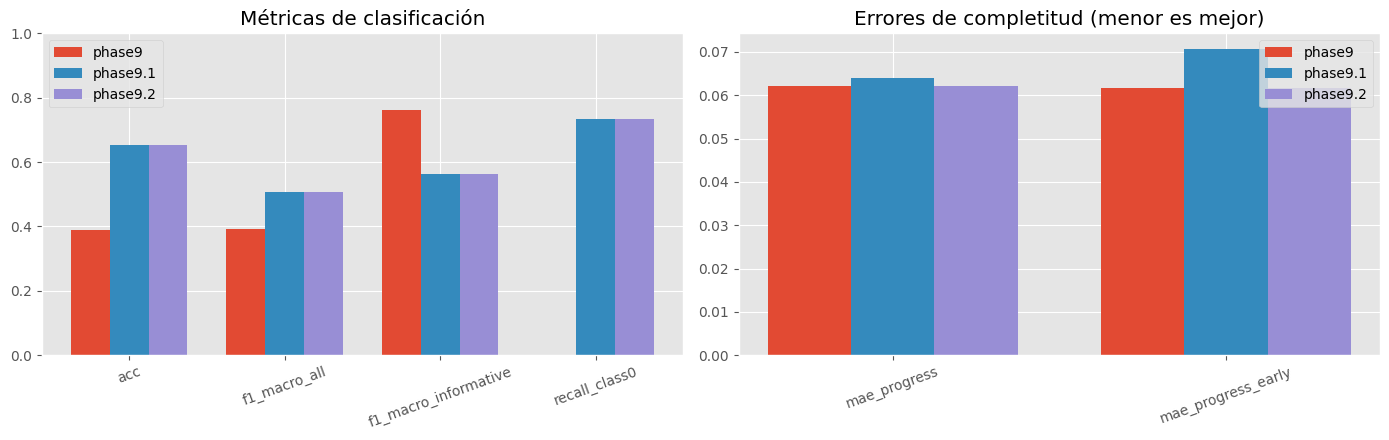

In [5]:
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Quality metrics higher better
m1 = cmp_m[cmp_m['metric'].isin(['acc','f1_macro_all','f1_macro_informative','recall_class0'])].copy()
x = np.arange(len(m1))
w = 0.25
axes[0].bar(x - w, m1['phase9'], width=w, label='phase9')
axes[0].bar(x, m1['phase9_1'], width=w, label='phase9.1')
axes[0].bar(x + w, m1['phase9_2'], width=w, label='phase9.2')
axes[0].set_xticks(x)
axes[0].set_xticklabels(m1['metric'], rotation=20)
axes[0].set_ylim(0, 1)
axes[0].set_title('Métricas de clasificación')
axes[0].legend()

# Errors lower better
m2 = cmp_m[cmp_m['metric'].isin(['mae_progress','mae_progress_early'])].copy()
x2 = np.arange(len(m2))
axes[1].bar(x2 - w, m2['phase9'], width=w, label='phase9')
axes[1].bar(x2, m2['phase9_1'], width=w, label='phase9.1')
axes[1].bar(x2 + w, m2['phase9_2'], width=w, label='phase9.2')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(m2['metric'], rotation=20)
axes[1].set_title('Errores de completitud (menor es mejor)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
print('Threshold híbrido usado:', s92['hybrid_threshold'])
print('Registry:', s92['outputs']['models_registry_json'])

Threshold híbrido usado: 0.5
Registry: ./phases/phase09_multitask_patterns/models_registry/phase9_models_registry.json


## Lectura rápida

- `phase9`: mejor en subclase informativa y completitud.
- `phase9.1`: mejor para separar ruido (class 0) y robustez global.
- `phase9.2`: compromiso práctico combinando ambos.
